## MTL Trajet: 09 Land-use Mode Route Weekday Patterns (Flag 9)

### Dataset Overview
Observed MTL urban trajectories ending in Mixte, economic-activity, or Agricole areas, with transport mode, route directness, endpoint, day-type, and timestamped route-point information. The eight agricultural records are weekly corridor repeats derived from two paired observed traces with bounded sub-30-metre lateral variations.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Identify the characteristics of three land-use types and their corresponding mobility behaviours from the trajectory data.

Role: Urban land-use and mobility analyst


Category: Destination land-use, transport mode, route directness, spatial distribution, and day type

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display
points=pd.read_csv('trajectory_points.csv')


## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do transport-mode compositions differ among Mixte, economic-activity, and Agricole destinations?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

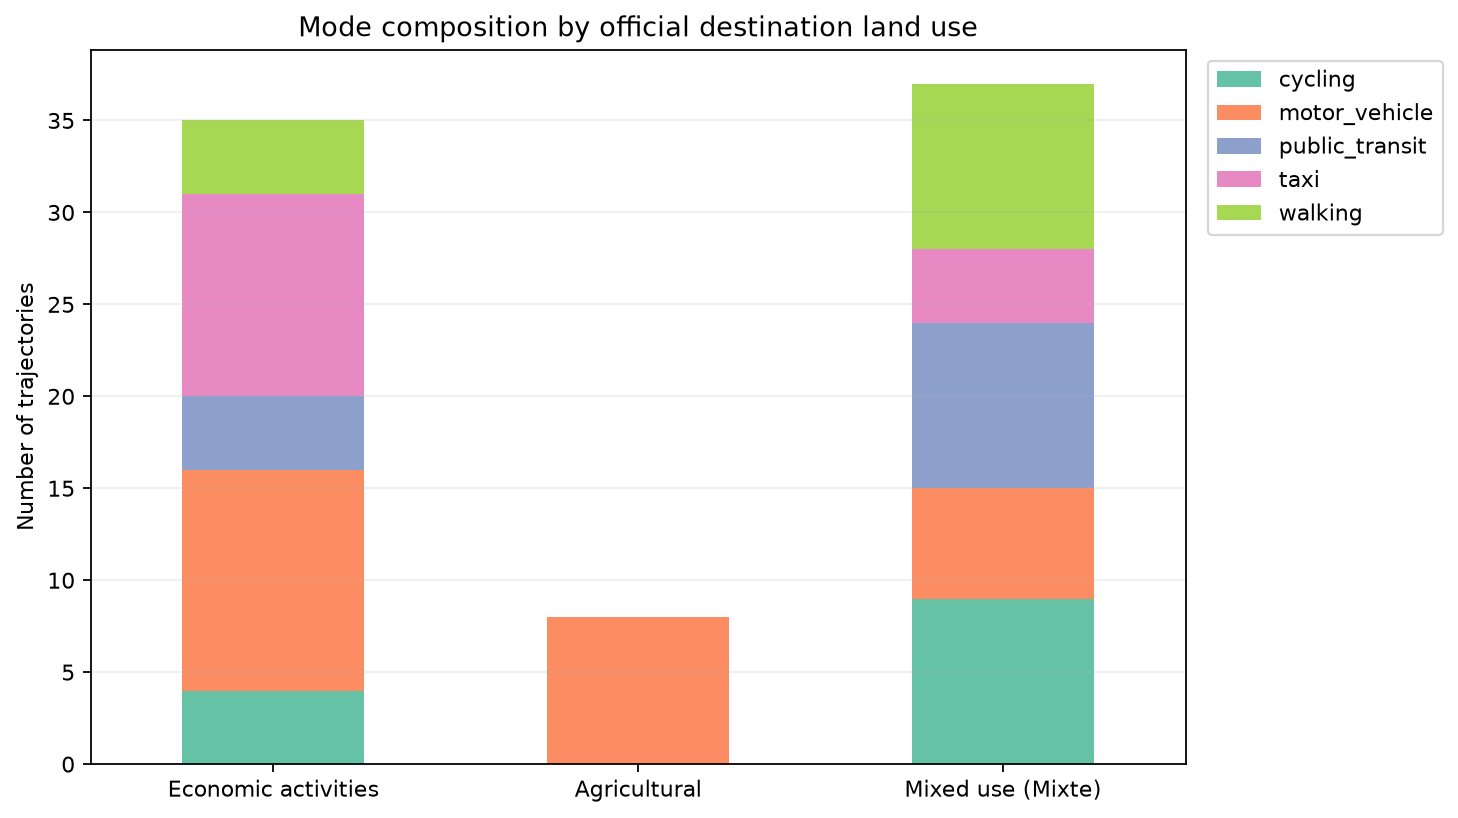

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv(dataset_path)
points = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))
print(pd.crosstab(df.destination_land_use, df.mode_group))

from IPython.display import Image, display
display(Image(filename='visualizations/mode_by_destination_land_use.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "land_use_mode_composition",
  "insight": "Mixte and economic-activity destinations each have diverse transport-mode compositions and share the same set of mode categories.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Transport Modes by Destination Land-use",
    "description": "Recomputed from the delivered fixed GPS coordinates and the archived official PUM2050 Affectatio polygons; Unmapped denotes no containing polygon.",
    "file": "visualizations/mode_by_destination_land_use.png"
  },
  "question": "How do transport-mode compositions differ among Mixte, economic-activity, and Agricole destinations?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\ndf = pd.read_csv(dataset_path)\npoints = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))\nprint(pd.crosstab(df.destination_land_use, df.mode_group))\n",
  "evidence": "Mixte and economic-activity destinations each have diverse transport-mode compositions and share the same set of mode categories.",
  "insight_value": {
    "cycling": {
      "Activités économiques": 4,
      "Agricole": 0,
      "Mixte": 9
    },
    "motor_vehicle": {
      "Activités économiques": 12,
      "Agricole": 8,
      "Mixte": 6
    },
    "public_transit": {
      "Activités économiques": 4,
      "Agricole": 0,
      "Mixte": 9
    },
    "taxi": {
      "Activités économiques": 11,
      "Agricole": 0,
      "Mixte": 4
    },
    "walking": {
      "Activités économiques": 4,
      "Agricole": 0,
      "Mixte": 9
    }
  },
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "land_use_reference",
    "transport_mode",
    "trajectory_id"
  ]
}

### **Question 2**: How similar are agricultural route directness and spatial paths, and which transport modes do they use?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

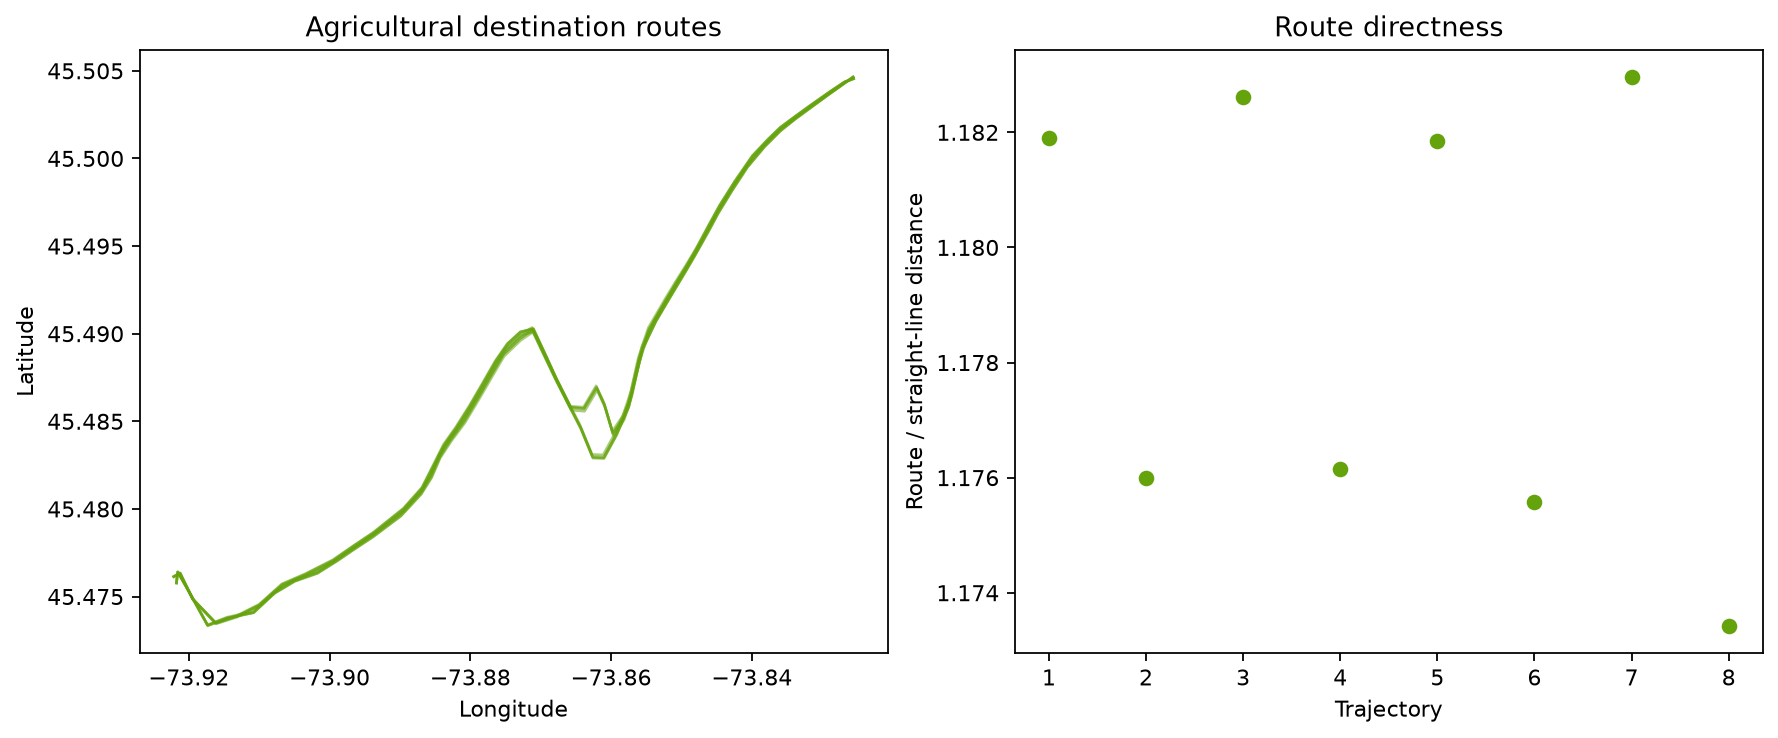

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv(dataset_path)
points = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))
a=df[df.destination_land_use.eq('Agricole')]; print(a[['mode_group','route_directness_ratio']].describe(include='all'))

from IPython.display import Image, display
display(Image(filename='visualizations/agricultural_route_directness_corridor.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "agricultural_route_corridor",
  "insight": "Agricultural-area trajectories are all motor-vehicle trips with nearly identical route-directness values and closely overlapping routes.",
  "insight_type": "overall_pattern",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Agricultural Route Directness and Corridor",
    "description": "Recomputed from the delivered fixed GPS coordinates and the archived official PUM2050 Affectatio polygons; Unmapped denotes no containing polygon.",
    "file": "visualizations/agricultural_route_directness_corridor.png"
  },
  "question": "How similar are agricultural route directness and spatial paths, and which transport modes do they use?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\ndf = pd.read_csv(dataset_path)\npoints = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))\na=df[df.destination_land_use.eq('Agricole')]; print(a[['mode_group','route_directness_ratio']].describe(include='all'))\n",
  "evidence": "Agricultural-area trajectories are all motor-vehicle trips with nearly identical route-directness values and closely overlapping routes.",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "land_use_reference",
    "transport_mode",
    "trajectory_id"
  ]
}

### **Question 3**: Where are Mixte, economic-activity, and Agricole destinations located relative to one another?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

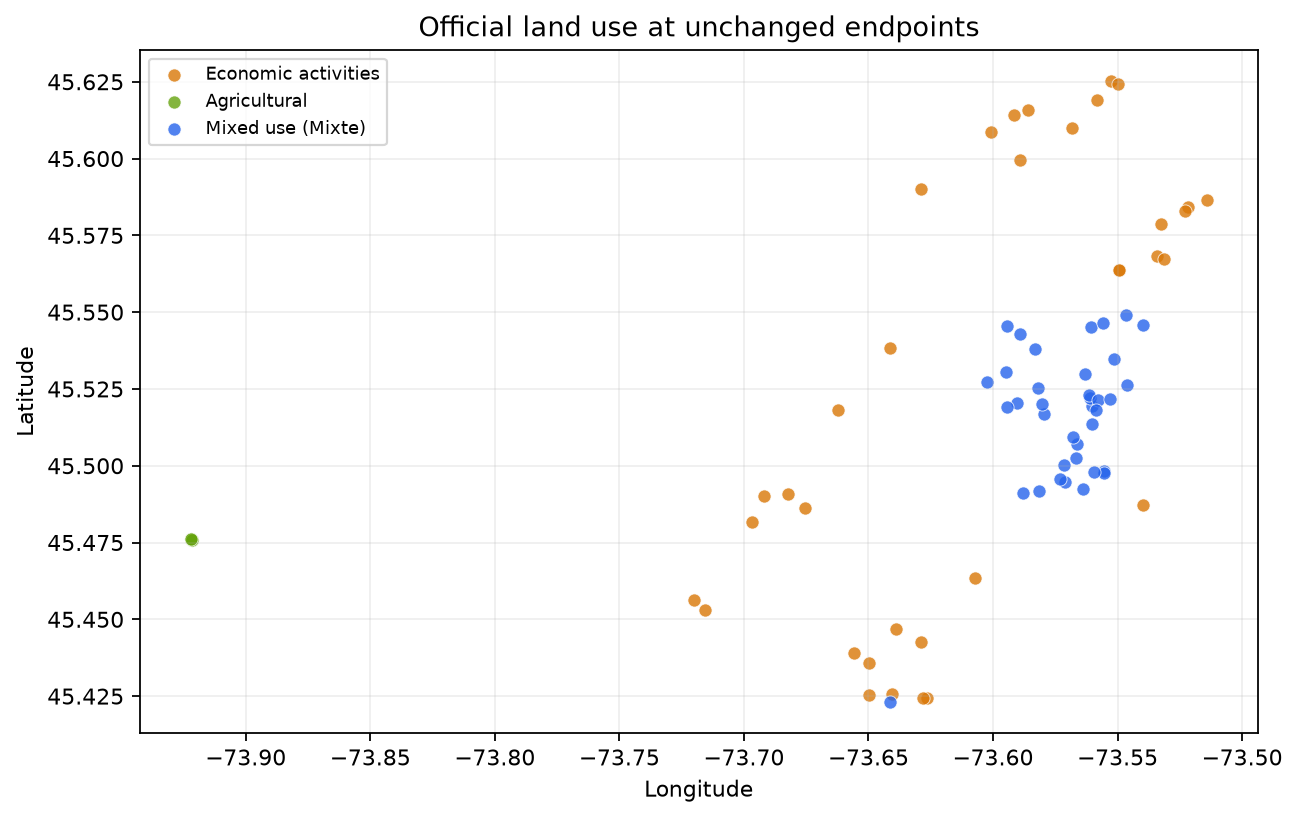

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv(dataset_path)
points = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))
print(df.groupby('destination_land_use')[['end_lon','end_lat']].agg(['min','max','mean']))

from IPython.display import Image, display
display(Image(filename='visualizations/land_use_spatial_distribution.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "land_use_spatial_distribution",
  "insight": "Mixte destinations occupy the central and eastern part of the study area; economic-activity destinations occur along the northern and southern edges as well as at scattered locations; agricultural destinations are confined to the southwest.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Spatial Distribution of Destination Land-use",
    "description": "Recomputed from the delivered fixed GPS coordinates and the archived official PUM2050 Affectatio polygons; Unmapped denotes no containing polygon.",
    "file": "visualizations/land_use_spatial_distribution.png"
  },
  "question": "Where are Mixte, economic-activity, and Agricole destinations located relative to one another?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\ndf = pd.read_csv(dataset_path)\npoints = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))\nprint(df.groupby('destination_land_use')[['end_lon','end_lat']].agg(['min','max','mean']))\n",
  "evidence": "Mixte destinations occupy the central and eastern part of the study area; economic-activity destinations occur along the northern and southern edges as well as at scattered locations; agricultural destinations are confined to the southwest.",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "land_use_reference",
    "trajectory_id"
  ]
}

### **Question 4**: Which destination land-use types occur on both weekdays and weekends?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

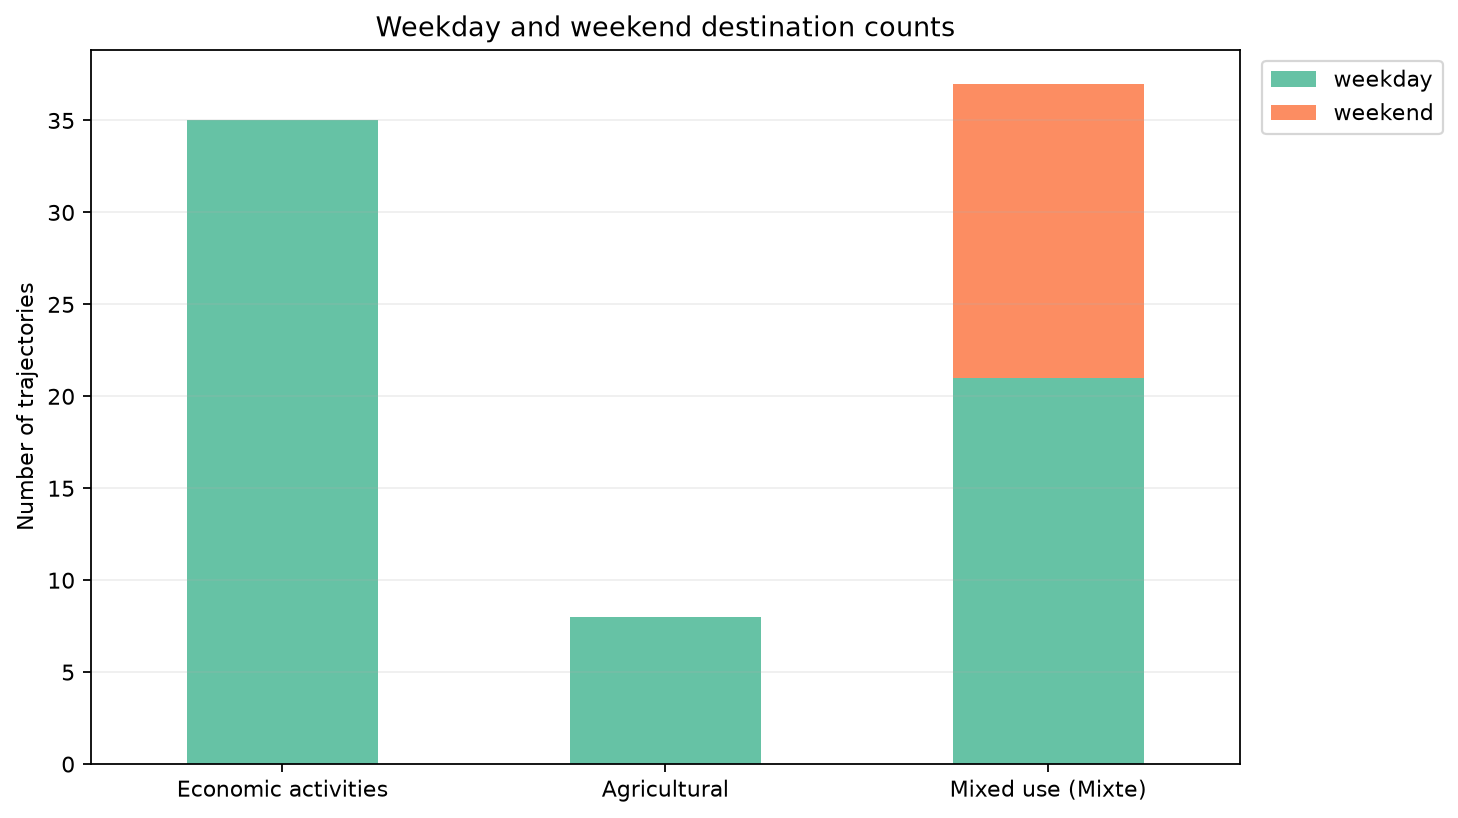

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv(dataset_path)
points = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))
print(pd.crosstab(df.destination_land_use, df.day_type))

from IPython.display import Image, display
display(Image(filename='visualizations/day_type_by_destination_land_use.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "land_use_day_type_presence",
  "insight": "Only Mixte-destination trajectories occur on both weekdays and weekends; economic-activity and agricultural destinations occur only on weekdays.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Day Type by Destination Land-use",
    "description": "Recomputed from the delivered fixed GPS coordinates and the archived official PUM2050 Affectatio polygons; Unmapped denotes no containing polygon.",
    "file": "visualizations/day_type_by_destination_land_use.png"
  },
  "question": "Which destination land-use types occur on both weekdays and weekends?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\ndf = pd.read_csv(dataset_path)\npoints = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))\nprint(pd.crosstab(df.destination_land_use, df.day_type))\n",
  "evidence": "Only Mixte-destination trajectories occur on both weekdays and weekends; economic-activity and agricultural destinations occur only on weekdays.",
  "insight_value": {
    "weekday": {
      "Activités économiques": 35,
      "Agricole": 8,
      "Mixte": 21
    },
    "weekend": {
      "Activités économiques": 0,
      "Agricole": 0,
      "Mixte": 16
    }
  },
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "land_use_reference",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 9)

Mixte and economic-activity destinations each have diverse transport-mode compositions and share the same set of mode categories. Agricultural-area trajectories are all motor-vehicle trips with nearly identical route-directness values and closely overlapping routes. Mixte destinations occupy the central and eastern part of the study area; economic-activity destinations occur along the northern and southern edges as well as at scattered locations; agricultural destinations are confined to the southwest. Only Mixte-destination trajectories occur on both weekdays and weekends; economic-activity and agricultural destinations occur only on weekdays.
